In [1]:
# %%
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split  # Importado para dividir treino/validação
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import pandas as pd
import matplotlib.pyplot as plt

/home/tom/Ferramentas/miniconda3/envs/mestrado/lib/python3.12/site-packages/torch/utils/_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


In [2]:
torch.manual_seed(42)
# %%
# Define o dispositivo: 'cuda' se disponível, caso contrário 'cpu'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando o dispositivo: {device}")


Usando o dispositivo: cuda


In [3]:
# %%
# Ordem dos datasets na extração de features RELU6-7
dataset_dict = {
    'Dataset1': ["Bel-Pao", "Copia", "ERV", "Gypsy", "L1", "Mariner", "Non-TE", "hAT"],
    'Dataset2': ["LINE", "LTR", "Non-TE", "CLASS II"],
    'Dataset3': ["Bel-Pao", "CACTA", "Copia", "ERV", "Gypsy", "L1", "Mariner", "Mutator", "PIF", "Non-TE", "SINE", "hAT"],
    'Dataset4': ["LINE", "LTR", "Non-TE", "SINE", "CLASS II"],
    'Dataset5': ["LINE", "LTR", "Non-TE", "CLASS II"]
}

# Ordem do artigo do TERL
dataset_dict_artigo = {
    'Dataset1': ["Copia", "Gypsy", "Bel-Pao", "ERV", "L1", "Mariner", "hAT", "Non-TE"],
    'Dataset2': ["LTR", "LINE", "CLASS II", "Non-TE"],
    'Dataset3': ["Copia", "Gypsy", "Bel-Pao", "ERV", "L1", "SINE", "Mariner", "hAT", "Mutator", "PIF", "CACTA", "Non-TE"],
    'Dataset4': ["LTR", "LINE", "SINE", "CLASS II", "Non-TE"],
    'Dataset5': ["LTR", "LINE", "CLASS II", "Non-TE"]
}

# De-para dos datasets
dataset_dict_ord_artigo = {
    'Dataset1': [1, 3, 0, 2, 4, 5, 7, 6],
    'Dataset2': [1, 0, 3, 2],
    'Dataset3': [2, 4, 0, 3, 5, 10, 6, 11, 7, 8, 1, 9],
    'Dataset4': [1, 0, 3, 4, 2],
    'Dataset5': [1, 0, 3, 2]
}


In [4]:
# %%
dataset = 'Dataset3'
dados_relu6 = '../Data/original_data/' + dataset + '/deep-features/'
dados_resnet_train = '../Data/deep-features/resnet/resnet_deep_features_train_' + dataset + '.npz'
dados_resnet_test = '../Data/deep-features/resnet/resnet_deep_features_test_' + dataset + '.npz'

# Dataset personalizado
class FeatureDataset(Dataset):
    def __init__(self, f1, f2, labels):
        self.f1 = torch.tensor(f1, dtype=torch.float32)
        self.f2 = torch.tensor(f2, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.f1[idx], self.f2[idx], self.labels[idx]

# Carregar dados
relu6_np = np.load(dados_relu6 + 'out_features_train_relu6.npy', allow_pickle=True)
resnet_np = np.load(dados_resnet_train)['features']
labels_np = np.load(dados_relu6 + 'out_labels_train.npy', allow_pickle=True).astype(np.int64)

# Divisão em treino e validação (80% treino, 20% validação)
def create_train_val_split(f1, f2, labels, val_split=0.2):
    f1_train, f1_val, f2_train, f2_val, labels_train, labels_val = train_test_split(
        f1, f2, labels, test_size=val_split, stratify=labels, random_state=42
    )
    train_data = FeatureDataset(f1_train, f2_train, labels_train)
    val_data = FeatureDataset(f1_val, f2_val, labels_val)
    return train_data, val_data

# Criar conjuntos de treino, validação e teste
train_data, val_data = create_train_val_split(relu6_np, resnet_np, labels_np)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_data = FeatureDataset(
    np.load(dados_relu6 + "out_features_test_relu6.npy", allow_pickle=True),
    np.load(dados_resnet_test)['features'],
    np.load(dados_relu6 + "out_labels_test.npy", allow_pickle=True).astype(np.int64)
)
test_loader = DataLoader(test_data, batch_size=32)

In [5]:
# =============================================
# 3. LATE FUSION PURA (classificadores independentes!)
# =============================================
class LateFusionClassifier(nn.Module):
    def __init__(self, dim1, dim2, hidden_dim=256, num_classes=10):
        super().__init__()

        # Ramo 1: classificador COMPLETO só para modalidade 1
        self.classifier1 = nn.Sequential(
            nn.Linear(dim1, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, num_classes)  # ← logits da modalidade 1
        )

        # Ramo 2: classificador COMPLETO só para modalidade 2
        self.classifier2 = nn.Sequential(
            nn.Linear(dim2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, num_classes)  # ← logits da modalidade 2
        )

        # Estratégia de combinação final (escolha uma!)
        self.fusion_strategy = "sum"  # opções: "sum", "mean", "max", "product", "concat+mlp"

        # OPCIONAL: se quiser concatenar + uma pequena MLP (chamada de "hybrid late fusion")
        self.hybrid_fusion = nn.Sequential(
            nn.Linear(num_classes * 2, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x1, x2):
        x1 = x1.squeeze(1)
        x2 = x2.squeeze(1)

        logits1 = self.classifier1(x1)  # [B, num_classes]
        logits2 = self.classifier2(x2)  # [B, num_classes]

        if self.fusion_strategy == "sum":
            return logits1 + logits2
        elif self.fusion_strategy == "mean":
            return (logits1 + logits2) / 2
        elif self.fusion_strategy == "max":
            return torch.max(logits1, logits2)
        elif self.fusion_strategy == "product":
            return logits1 * logits2
        else:  # concat + mlp (hybrid)
            x = torch.cat([logits1, logits2], dim=-1)
            return self.hybrid_fusion(x)

In [6]:
# %%
# Parâmetros do modelo
feat1_dim = relu6_np.shape[-1]
feat2_dim = resnet_np.shape[-1]
embed_dim = 512
num_classes = len(np.unique(labels_np))

In [7]:
# Inicializar modelo, otimizador e critério
model = LateFusionClassifier(feat1_dim, feat2_dim, embed_dim, num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)  # Adicionada regularização L2
criterion = nn.CrossEntropyLoss()

# Função para calcular acurácia
def calculate_accuracy(outputs, labels):
    _, preds = torch.max(outputs, 1)
    correct = (preds == labels).float().sum()
    return correct / labels.shape[0]

# Treinamento com early stopping
num_epochs = 100
patience = 100  # Número de épocas para esperar antes de parar
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_path = f"late_fusion_concat_{dataset}.pt"

# Listas para armazenar métricas de treinamento e validação
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    # Treinamento
    model.train()
    train_loss = 0
    train_acc = 0
    for f1, f2, labels in train_loader:
        f1, f2, labels = f1.to(device), f2.to(device), labels.to(device)
        optimizer.zero_grad()
        output = model(f1, f2)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_acc += calculate_accuracy(output, labels).item()

    train_loss /= len(train_loader)
    train_acc /= len(train_loader)
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validação
    model.eval()
    val_loss = 0
    val_acc = 0
    with torch.no_grad():
        for f1, f2, labels in val_loader:
            f1, f2, labels = f1.to(device), f2.to(device), labels.to(device)
            output = model(f1, f2)
            val_loss += criterion(output, labels).item()
            val_acc += calculate_accuracy(output, labels).item()

    val_loss /= len(val_loader)
    val_acc /= len(val_loader)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.4f}, "
          f"Val Loss = {val_loss:.4f}, Val Acc = {val_acc:.4f}")

    # Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), best_model_path)  # Salvar o melhor modelo
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs")
            break


Epoch 1: Train Loss = 0.1893, Train Acc = 0.9488, Val Loss = 0.1450, Val Acc = 0.9592
Epoch 2: Train Loss = 0.1578, Train Acc = 0.9559, Val Loss = 0.1418, Val Acc = 0.9622
Epoch 3: Train Loss = 0.1645, Train Acc = 0.9553, Val Loss = 0.1319, Val Acc = 0.9628
Epoch 4: Train Loss = 0.1559, Train Acc = 0.9571, Val Loss = 0.1392, Val Acc = 0.9633
Epoch 5: Train Loss = 0.1561, Train Acc = 0.9564, Val Loss = 0.1378, Val Acc = 0.9611
Epoch 6: Train Loss = 0.1550, Train Acc = 0.9576, Val Loss = 0.1315, Val Acc = 0.9625
Epoch 7: Train Loss = 0.1514, Train Acc = 0.9586, Val Loss = 0.1333, Val Acc = 0.9638
Epoch 8: Train Loss = 0.1560, Train Acc = 0.9567, Val Loss = 0.1294, Val Acc = 0.9628
Epoch 9: Train Loss = 0.1505, Train Acc = 0.9583, Val Loss = 0.1228, Val Acc = 0.9657
Epoch 10: Train Loss = 0.1545, Train Acc = 0.9584, Val Loss = 0.1357, Val Acc = 0.9615
Epoch 11: Train Loss = 0.1559, Train Acc = 0.9579, Val Loss = 0.1344, Val Acc = 0.9606
Epoch 12: Train Loss = 0.1507, Train Acc = 0.9583, V

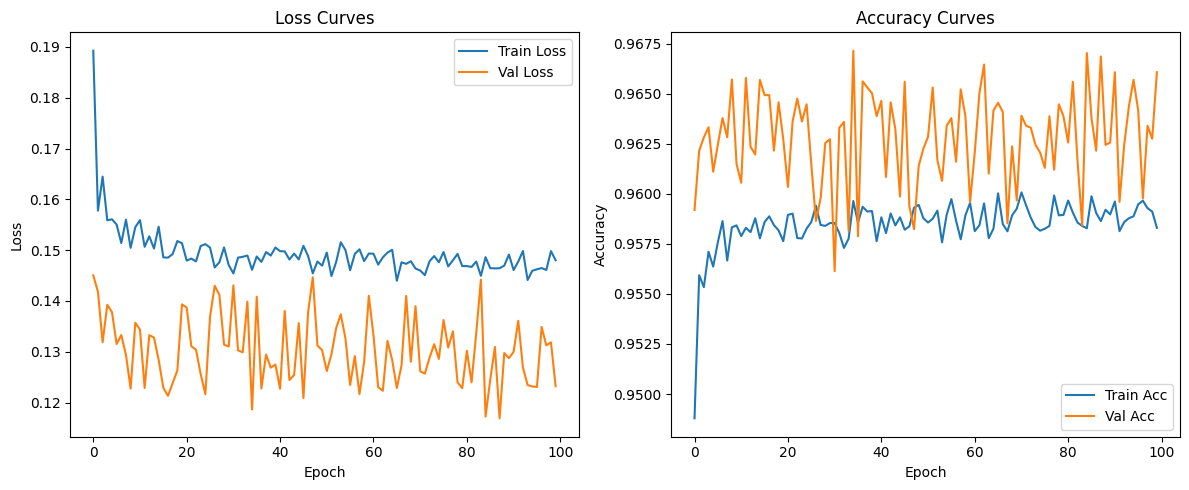

In [8]:
# Plotar curvas de aprendizado
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Acc')
plt.plot(val_accuracies, label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy Curves')
plt.tight_layout()
plt.show()


In [9]:
# Carregar o melhor modelo para avaliação
model.load_state_dict(torch.load(best_model_path))

# Avaliação no conjunto de teste
all_preds = []
all_labels = []
model.eval()
with torch.no_grad():
    for f1, f2, labels in test_loader:
        outputs = model(f1.to(device), f2.to(device))
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

[[369  81  31   6   2   2   1   4   0   5  30  14]
 [ 66 351  32  11   7   1   2   2   3   4  33  33]
 [  5  14 517   0   0   0   3   1   0   0   3   2]
 [ 32 119   1 351  18   1   0   0   0   2  10  11]
 [ 34  76   3   1 354   6   4   3   0  10  37  17]
 [  0   3   0   0   0 524   0   3   1   1   7   6]
 [  0   0   0   0   0   0 532   0   1   2   6   4]
 [ 12  21   1   0   0   2   1 449   9   6  31  13]
 [  0   0   0   0   0   1   0   0 537   0   6   1]
 [  2   3   0   0   0   3   4   1   4 510   9   9]
 [ 10  40   0   0   0   2   3   6   4   9 444  27]
 [  0  18   1   0   0   2   5   0   2   2  14 501]]


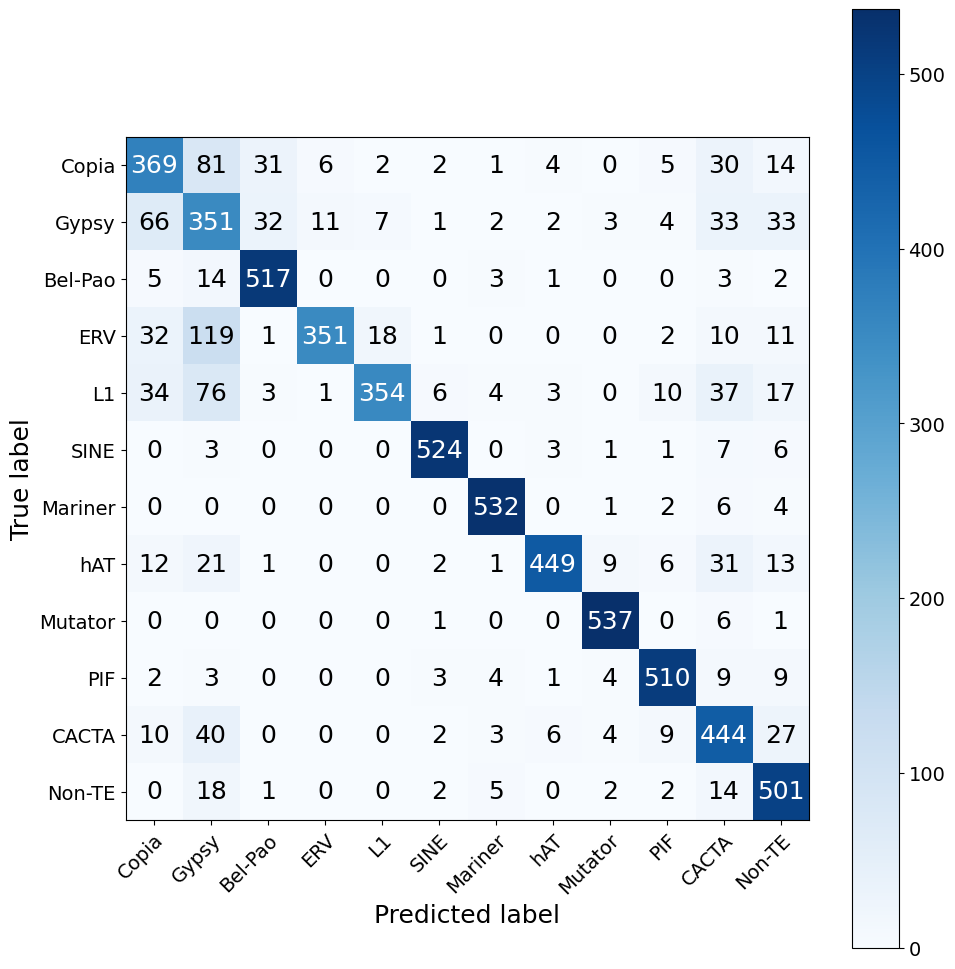

In [10]:
# Criar a matriz de confusão
cm = confusion_matrix(all_labels, all_preds)
labels = dataset_dict[dataset]

# Reordenar a matriz de confusão
new_order = dataset_dict_ord_artigo[dataset]
cm_reordered = cm[new_order, :]
cm_reordered = cm_reordered[:, new_order]
print(cm_reordered)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_reordered, display_labels=dataset_dict_artigo[dataset])
cm_reordered = disp.confusion_matrix
lbls = dataset_dict_artigo[dataset]
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(cm_reordered, interpolation='nearest', cmap='Blues')

# Rótulos dos eixos
ax.set_xlabel('Predicted label', fontsize=18)
ax.set_ylabel('True label', fontsize=18)
ax.set_xticks(np.arange(len(lbls)))
ax.set_yticks(np.arange(len(lbls)))
ax.set_xticklabels(lbls, fontsize=14)
ax.set_yticklabels(lbls, fontsize=14)

# Rotacionar os rótulos do eixo X
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Anotações dos valores
for t in range(cm_reordered.shape[0]):
    for j in range(cm_reordered.shape[1]):
        color = "white" if t == j else "black"
        ax.text(j, t, f"{int(cm_reordered[t, j])}", ha="center", va="center", color=color, fontsize=18)

# Barra de cores
cbar = ax.figure.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=14)
plt.tight_layout()
plt.show()

In [11]:
# Relatório de classificação
metrics = classification_report(all_labels, all_preds, target_names=labels, output_dict=True)
metrics_df = pd.DataFrame(metrics).transpose()

# Funções para métricas por classe
def accuracy_by_class(cm):
    accuracies = []
    num_classes = cm.shape[0]
    for i in range(num_classes):
        TP = cm[i, i]
        TN = np.sum(cm) - np.sum(cm[i, :]) - np.sum(cm[:, i]) + TP
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        total = TP + TN + FP + FN
        accuracy = (TP + TN) / total if total > 0 else 0.0
        accuracies.append(accuracy)
    return accuracies

def format_by_class(metrics_by_class, labels):
    return [f'{labels[i]}: {x:.3f}' for i, x in enumerate(metrics_by_class)]

def specificity(cm):
    specifics = []
    for i in range(cm.shape[0]):
        TN = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
        FP = np.sum(cm[:, i]) - cm[i, i]
        specificity_value = TN / (TN + FP)
        specifics.append(specificity_value)
    return specifics

# Calcular métricas
acc_by_class = accuracy_by_class(cm_reordered)
print("Acurácia por classe: ", format_by_class(acc_by_class, labels))
accuracy_macro = np.mean(acc_by_class)
print(f"Acurácia Macro: {accuracy_macro:.3f}")
specificity_by_class = specificity(cm_reordered)
print("Especificidade por classe: ", format_by_class(specificity_by_class, labels))
specificity_macro = np.mean(specificity_by_class)
print(f"Especificidade Macro: {specificity_macro:.3f}")

# Atualizar DataFrame com métricas
df_new = metrics_df.iloc[:-3].copy()
df_new['specificity'] = specificity_by_class
df_new['acc'] = acc_by_class
new_column_order = ['acc', 'precision', 'recall', 'f1-score', 'specificity', 'support']
df_new = df_new.reindex(columns=new_column_order)

# Calcular a média das colunas
mean_row = df_new.mean(numeric_only=True)
mean_row_df = pd.DataFrame([mean_row], index=['Mean'], columns=df_new.columns)
df_new = pd.concat([df_new, mean_row_df])

# Exibir DataFrame final
print(df_new)

Acurácia por classe:  ['Bel-Pao: 0.948', 'CACTA: 0.913', 'Copia: 0.985', 'ERV: 0.968', 'Gypsy: 0.967', 'L1: 0.994', 'Mariner: 0.994', 'Mutator: 0.982', 'PIF: 0.995', 'Non-TE: 0.988', 'SINE: 0.956', 'hAT: 0.972']
Acurácia Macro: 0.972
Especificidade por classe:  ['Bel-Pao: 0.973', 'CACTA: 0.937', 'Copia: 0.988', 'ERV: 0.997', 'Gypsy: 0.995', 'L1: 0.997', 'Mariner: 0.996', 'Mutator: 0.997', 'PIF: 0.996', 'Non-TE: 0.993', 'SINE: 0.969', 'hAT: 0.977']
Especificidade Macro: 0.985
              acc  precision    recall  f1-score  specificity  support
Bel-Pao  0.948471   0.882253  0.948624  0.914235     0.973144    545.0
CACTA    0.912997   0.704762  0.814679  0.755745     0.937448    545.0
Copia    0.985168   0.696226  0.677064  0.686512     0.988490    545.0
ERV      0.967584   0.951220  0.644037  0.768053     0.996997    545.0
Gypsy    0.966667   0.483471  0.644037  0.552321     0.995496    545.0
L1       0.993731   0.929134  0.649541  0.764579     0.996664    545.0
Mariner  0.994495   0.9